In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
delivery = pd.read_csv('delivery_data.csv')

Exploratory data analysis

In [4]:
print("Shape of data:",delivery.shape)

Shape of data: (502000, 26)


In [5]:
print("Columns:",delivery.columns.tolist())

Columns: ['order_id', 'order_datetime', 'seller_id', 'warehouse_city', 'destination_city', 'city_tier', 'region', 'distance_km', 'product_category', 'product_weight_kg', 'is_fragile', 'product_price', 'discount_pct', 'payment_method', 'courier_partner', 'shipping_mode', 'seller_handling_hours', 'weather', 'traffic_level', 'is_festival_season', 'promised_days', 'promised_delivery_date', 'actual_delivery_datetime', 'actual_days', 'delay_days', 'is_late']


In [6]:
print("Data Types:")
print(delivery.dtypes)

Data Types:
order_id                        str
order_datetime                  str
seller_id                       str
warehouse_city                  str
destination_city                str
city_tier                     int64
region                          str
distance_km                 float64
product_category                str
product_weight_kg           float64
is_fragile                    int64
product_price               float64
discount_pct                  int64
payment_method                  str
courier_partner                 str
shipping_mode                   str
seller_handling_hours       float64
weather                         str
traffic_level                   str
is_festival_season            int64
promised_days                 int64
promised_delivery_date          str
actual_delivery_datetime        str
actual_days                   int64
delay_days                    int64
is_late                       int64
dtype: object


In [7]:
delivery.describe()

,city_tier,distance_km,product_weight_kg,is_fragile,product_price,discount_pct,seller_handling_hours,is_festival_season,promised_days,actual_days,delay_days,is_late
count,502000.000000,502000.000000,496976.000000,502000.000000,502000.000000,502000.000000,491957.000000,502000.00000,502000.000000,502000.000000,502000.000000,502000.000000
mean,1.899542,1430.385922,4.770637,0.210418,1482.718602,13.769034,28.977413,0.13411,5.747183,6.030831,0.480145,0.209422
std,0.767082,738.930236,6.840151,0.407606,1944.569156,15.325882,11.511920,0.34077,2.169214,2.871880,1.136298,0.406897
min,1.000000,5.000000,0.100000,0.000000,9.490000,0.000000,2.000000,0.00000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,776.000000,1.050000,0.000000,458.320000,0.000000,20.900000,0.00000,4.000000,4.000000,0.000000,0.000000
50%,2.000000,1565.500000,2.110000,0.000000,898.655000,10.000000,28.400000,0.00000,6.000000,6.000000,0.000000,0.000000
75%,2.000000,1965.700000,6.500000,0.000000,1767.670000,20.000000,36.500000,0.00000,8.000000,8.000000,0.000000,0.000000
max,3.000000,2817.200000,389.700000,1.000000,114238.150000,50.000000,88.500000,1.00000,10.000000,20.000000,10.000000,1.000000


In [8]:
delivery.head()

,order_id,order_datetime,seller_id,warehouse_city,destination_city,city_tier,region,distance_km,product_category,product_weight_kg,...,seller_handling_hours,weather,traffic_level,is_festival_season,promised_days,promised_delivery_date,actual_delivery_datetime,actual_days,delay_days,is_late
0,ORD100000,2025-01-01 00:00:00,S1753,Bengaluru,Chandigarh,2,North,2462.3,Books,1.25,...,23.2,Clear,High,0,9,2025-01-10,2025-01-12 00:00:00,11,2,1
1,ORD100001,2025-01-01 00:01:00,S1895,Mumbai,Mumbai,1,West,9.7,Clothing,1.56,...,16.0,Fog,Medium,0,0,2025-01-01,2025-01-01 20:52:00,0,0,0
2,ORD100002,2025-01-01 00:01:00,S0122,Kolkata,Mumbai,1,West,2070.1,Clothing,1.84,...,22.5,Clear,Medium,0,8,2025-01-09,2025-01-08 00:01:00,7,0,0
3,ORD100003,2025-01-01 00:04:00,S0623,Delhi,Imphal,3,East,2137.8,Clothing,0.97,...,33.9,Fog,Medium,0,4,2025-01-05,2025-01-05 00:04:00,4,0,0
4,ORD100004,2025-01-01 00:05:00,S1868,Delhi,Shimla,3,North,347.5,Clothing,1.64,...,40.1,Heavy Rain,Medium,0,4,2025-01-05,2025-01-07 00:05:00,6,2,1


In [9]:
delivery.tail()

,order_id,order_datetime,seller_id,warehouse_city,destination_city,city_tier,region,distance_km,product_category,product_weight_kg,...,seller_handling_hours,weather,traffic_level,is_festival_season,promised_days,promised_delivery_date,actual_delivery_datetime,actual_days,delay_days,is_late
501995,ORD392133,2025-08-02 08:59:00,S1517,Bengaluru,Chennai,1,South,365.9,Electronics,6.89,...,7.6,Clear,High,0,4,2025-08-06,2025-08-06 08:59:00,4,0,0
501996,ORD367480,2025-07-15 09:30:00,S0337,Kolkata,Shimla,3,North,1821.4,Electronics,5.20,...,24.0,Rain,Low,0,8,2025-07-23,2025-07-25 09:30:00,10,2,1
501997,ORD433117,2025-09-01 08:54:00,S0777,Bengaluru,Guwahati,3,East,2589.1,Books,1.58,...,30.6,Rain,High,0,9,2025-09-10,2025-09-12 08:54:00,11,2,1
501998,ORD501268,2025-10-20 19:52:00,S0493,Delhi,Bhubaneswar,2,East,1584.7,Electronics,4.84,...,41.1,Clear,Medium,1,7,2025-10-27,2025-10-29 19:52:00,9,2,1
501999,ORD283549,2025-05-14 22:19:00,S0301,Bengaluru,Guwahati,3,East,2589.1,Beauty,0.72,...,NaN,NaN,Medium,0,9,2025-05-23,2025-05-26 22:19:00,12,3,1


In [10]:
print("Null values:")
delivery.isnull().sum()

Null values:


order_id                        0
order_datetime                  0
seller_id                       0
warehouse_city                  0
destination_city                0
city_tier                       0
region                          0
distance_km                     0
product_category                0
product_weight_kg            5024
is_fragile                      0
product_price                   0
discount_pct                    0
payment_method                  0
courier_partner                 0
shipping_mode                   0
seller_handling_hours       10043
weather                     10043
traffic_level                7534
is_festival_season              0
promised_days                   0
promised_delivery_date          0
actual_delivery_datetime        0
actual_days                     0
delay_days                      0
is_late                         0
dtype: int64

In [11]:
print("Duplicate rows:",delivery.duplicated().sum())
print("Duplicate order id's:",delivery['order_id'].duplicated().sum())

Duplicate rows: 2000
Duplicate order id's: 2000


In [12]:
print(("Orders with distance <= 0:",(delivery['distance_km']<=0).sum()))
print(("Orders with price <= 0:",(delivery['product_price']<=0).sum()))
print(("Orders with weight <= 0:",(delivery['product_weight_kg']<=0).sum()))
print(("Orders with discount < 0 or > 100:",(delivery['discount_pct']<0).sum() | (delivery['discount_pct']>100).sum()))

('Orders with distance <= 0:', np.int64(0))
('Orders with price <= 0:', np.int64(0))
('Orders with weight <= 0:', np.int64(0))
('Orders with discount < 0 or > 100:', np.int64(0))


Target Analysis

In [13]:
print("Skewness of target(actual_days):",delivery['actual_days'].skew())
print("Kurtosis of target(actual_days):",delivery['actual_days'].kurt())

Skewness of target(actual_days): 0.5282825606403477


Kurtosis of target(actual_days): 0.21537369990854494


In [14]:
cols = ['distance_km','product_weight_kg','seller_handling_hours','promised_days','actual_days','delay_days']

In [15]:
for c in cols:
    print("Minimum value in",c,':',delivery[c].min())

Minimum value in distance_km : 5.0
Minimum value in product_weight_kg : 0.1
Minimum value in seller_handling_hours : 2.0
Minimum value in promised_days : 0
Minimum value in actual_days : 0
Minimum value in delay_days : 0


In [16]:
for c in cols:
    print("Maximum value in",c,":",delivery[c].max())

Maximum value in distance_km : 2817.2
Maximum value in product_weight_kg : 389.7
Maximum value in seller_handling_hours : 88.5
Maximum value in promised_days : 10
Maximum value in actual_days : 20
Maximum value in delay_days : 10


In [17]:
for c in cols:
    print("Mean of",c,":",delivery[c].mean())

Mean of distance_km : 1430.3859219123506
Mean of product_weight_kg : 4.770637415086442
Mean of seller_handling_hours : 28.977413269858953
Mean of promised_days : 5.747183266932271
Mean of actual_days : 6.030830677290837
Mean of delay_days : 0.4801454183266932


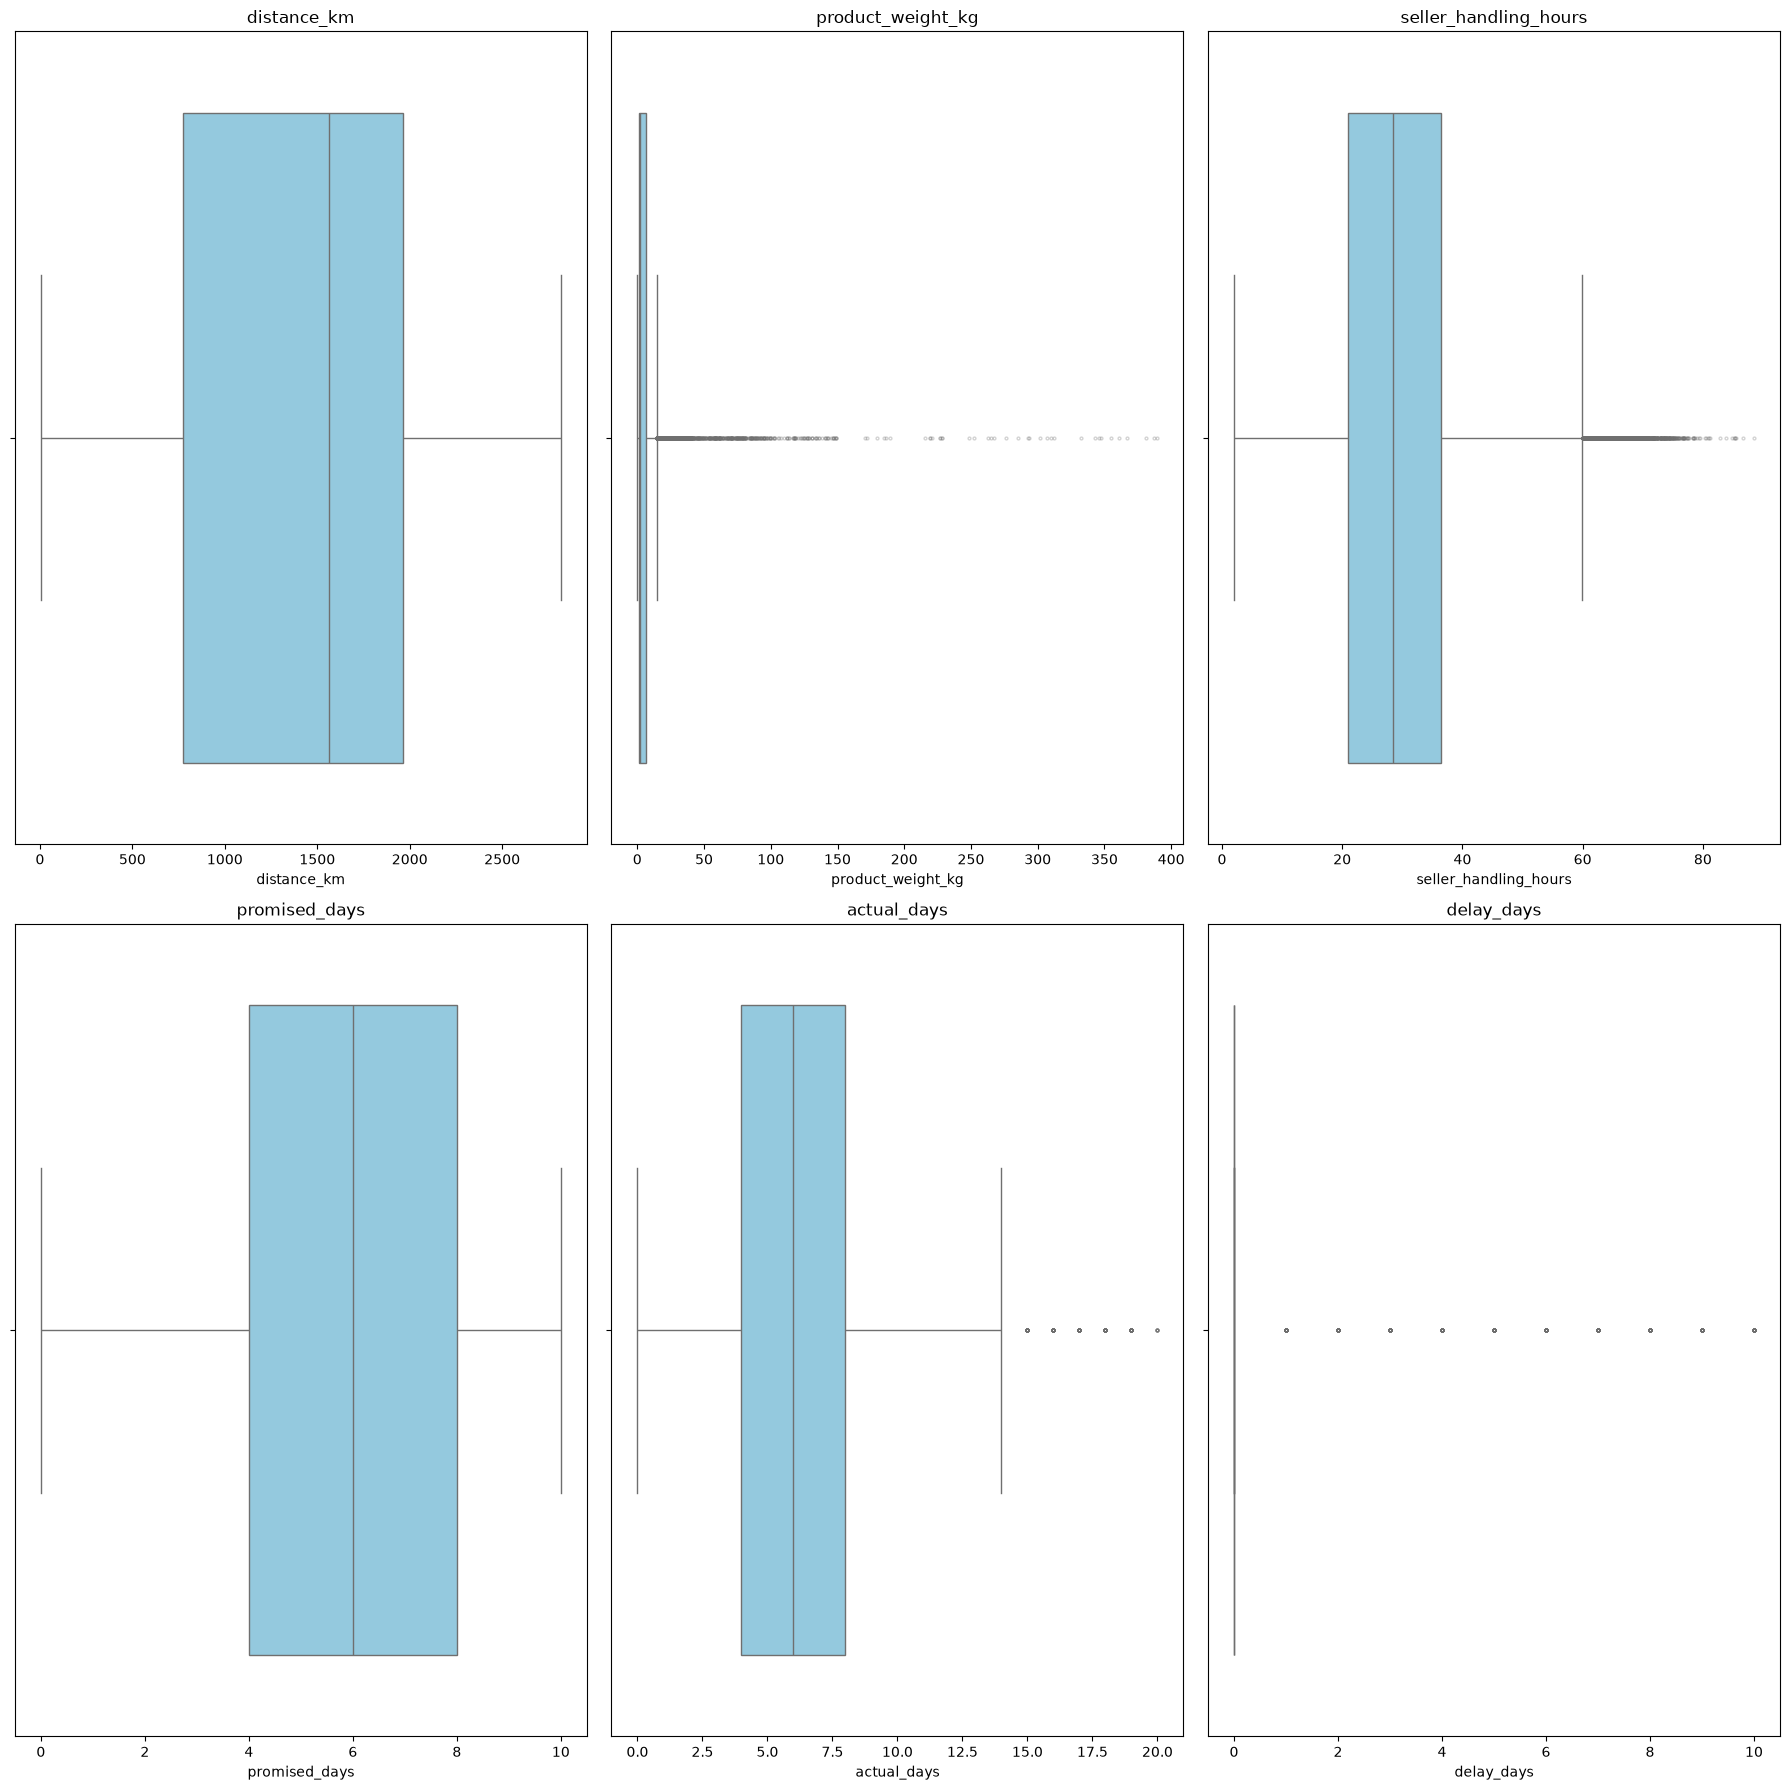

In [18]:
fig,axes = plt.subplots(2,3,figsize=(18,18))
axes = axes.flatten()
for ax,col in zip(axes,cols):
    sns.boxplot(x=delivery[col],ax=ax,color='skyblue',flierprops={'markersize':2,'alpha':0.3})
    ax.set_title(col)

plt.tight_layout()
plt.show()

In [19]:
delivery['order_datetime'] = pd.to_datetime(delivery['order_datetime'])
delivery['order_month'] = delivery['order_datetime'].dt.month
delivery['order_day'] = delivery['order_datetime'].dt.dayofweek
delivery['order_hour'] = delivery['order_datetime'].dt.hour

print(delivery['order_datetime'].dtypes)
print(delivery[['order_month','order_day','order_hour']].head())

datetime64[us]
   order_month  order_day  order_hour
0            1          2           0
1            1          2           0
2            1          2           0
3            1          2           0
4            1          2           0


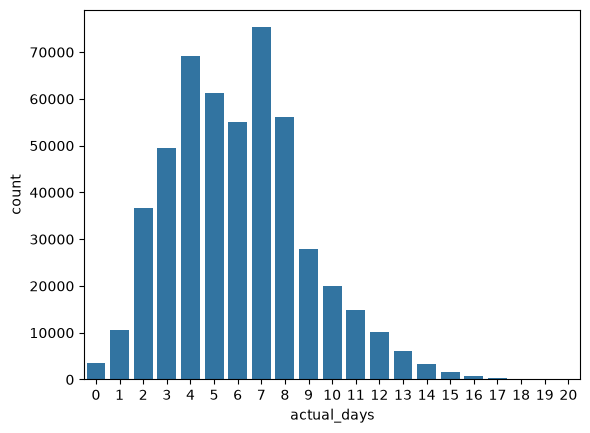

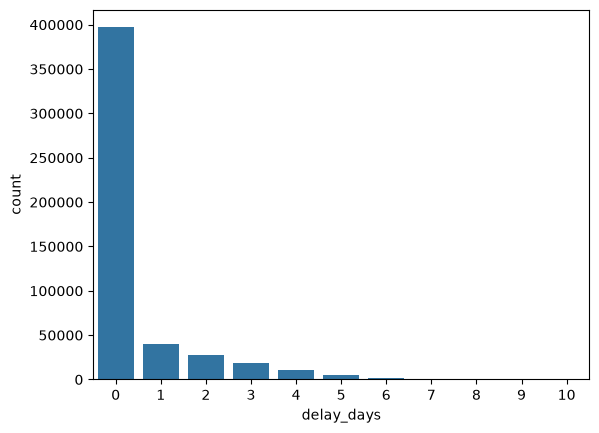

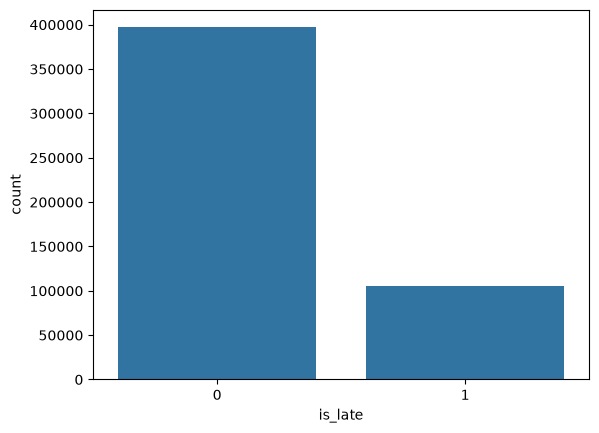

In [20]:
sns.countplot(x = 'actual_days',data=delivery); plt.show()
sns.countplot(x='delay_days',data=delivery); plt.show()
sns.countplot(x='is_late', data=delivery); plt.show()

In [21]:
num_cols = ['distance_km', 'product_weight_kg', 'product_price', 'discount_pct','seller_handling_hours', 'promised_days']

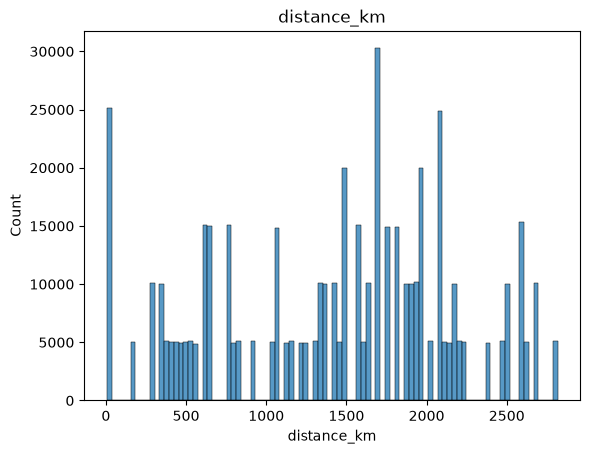

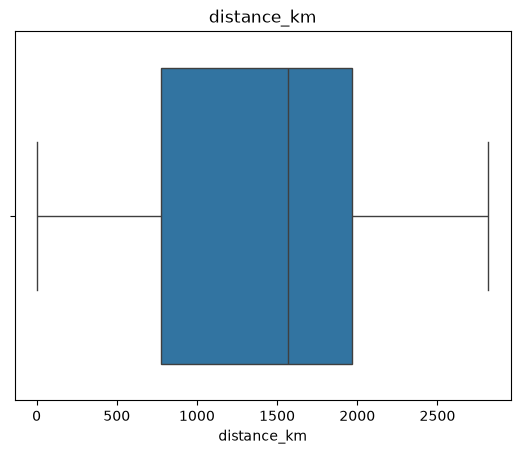

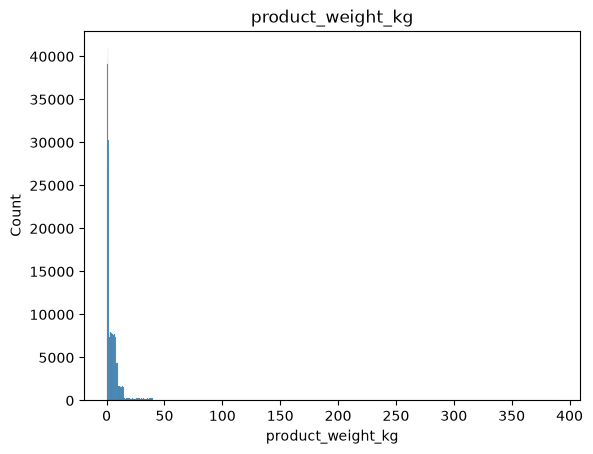

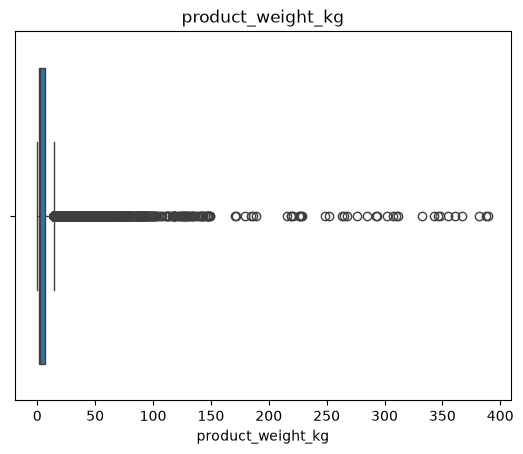

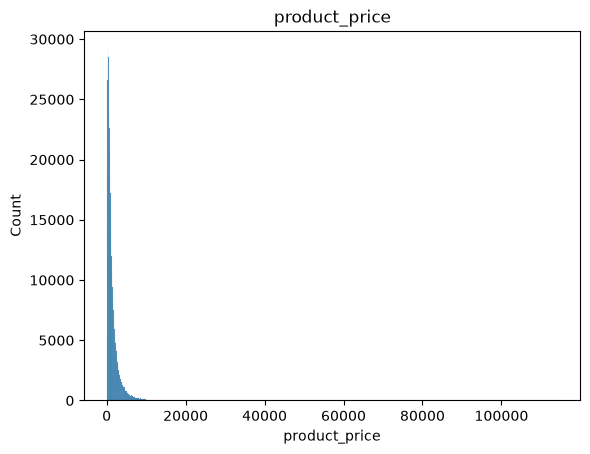

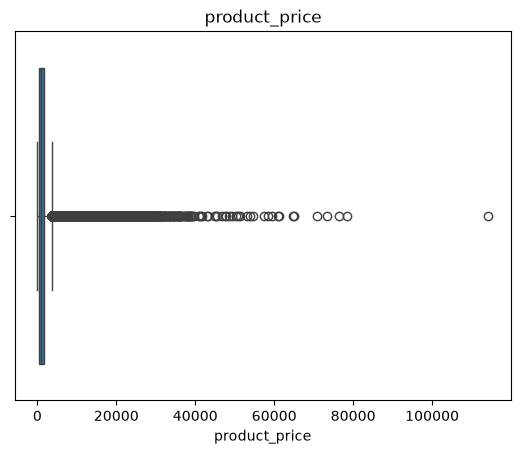

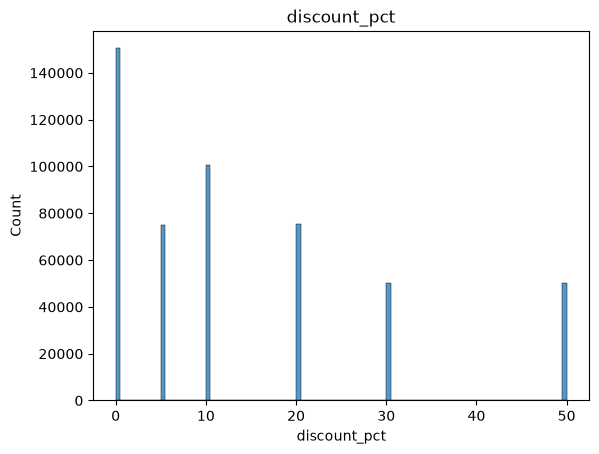

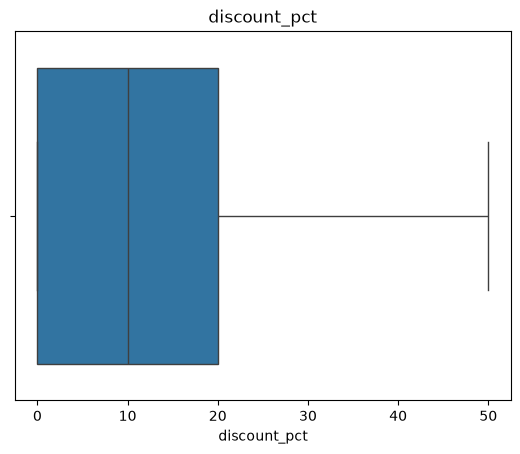

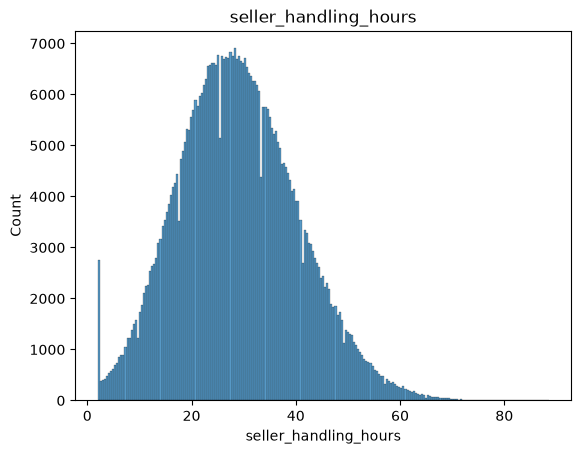

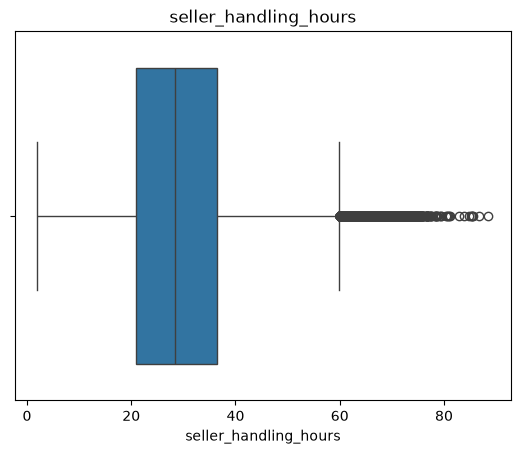

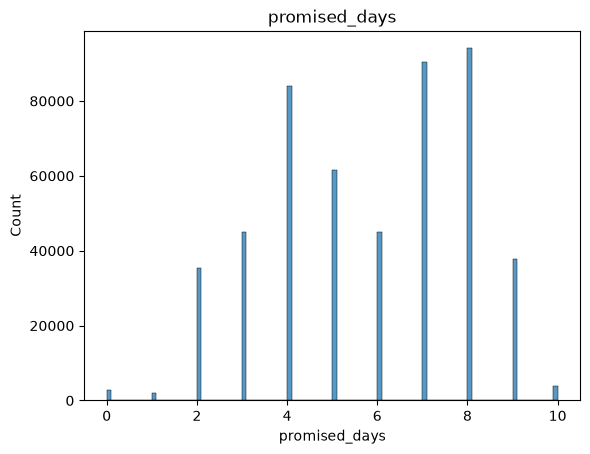

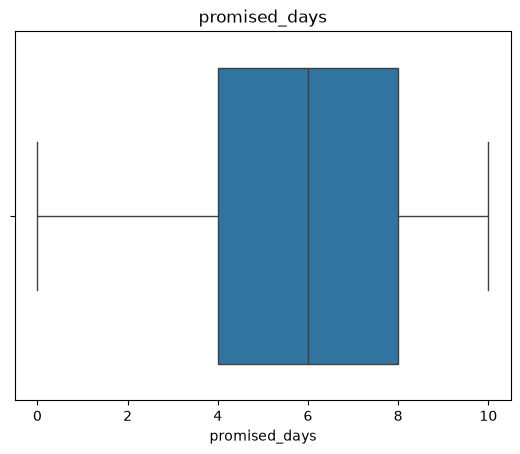

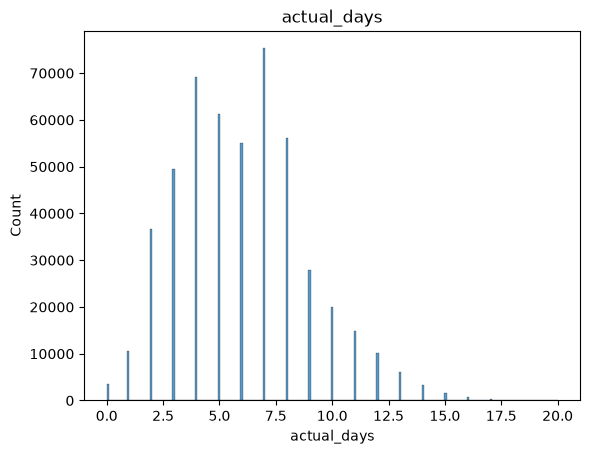

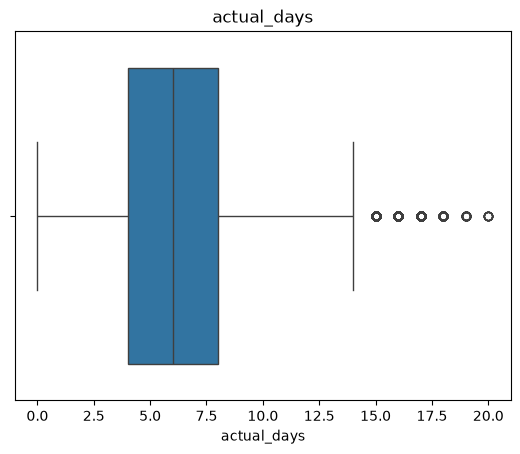

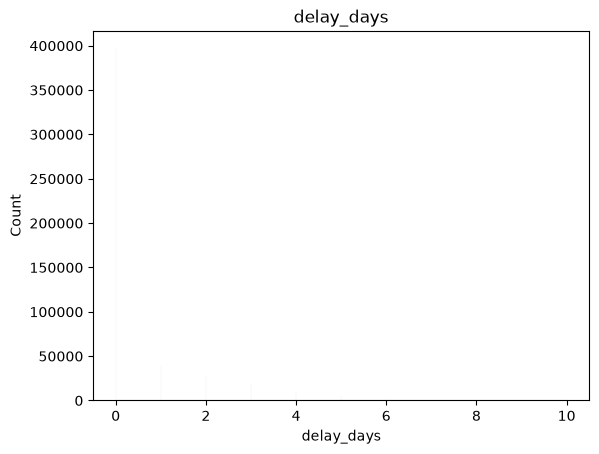

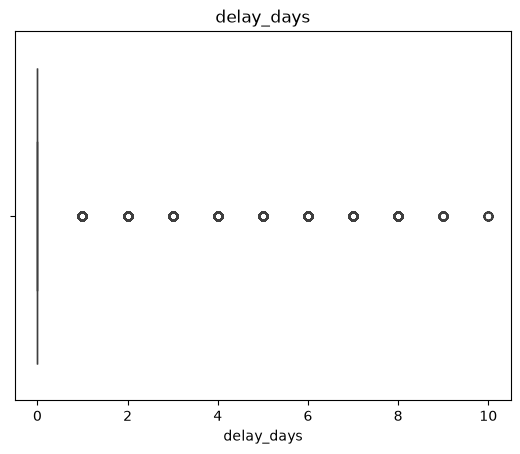

In [22]:
for col in num_cols + ['actual_days', 'delay_days']:
    sns.histplot(delivery[col]); plt.title(col); plt.show()
    sns.boxplot(x=delivery[col]); plt.title(col); plt.show()

In [23]:
cat_cols = ['region', 'city_tier', 'product_category', 'payment_method', 'courier_partner', 'shipping_mode', 'weather', 'traffic_level', 'is_fragile', 'is_festival_season']

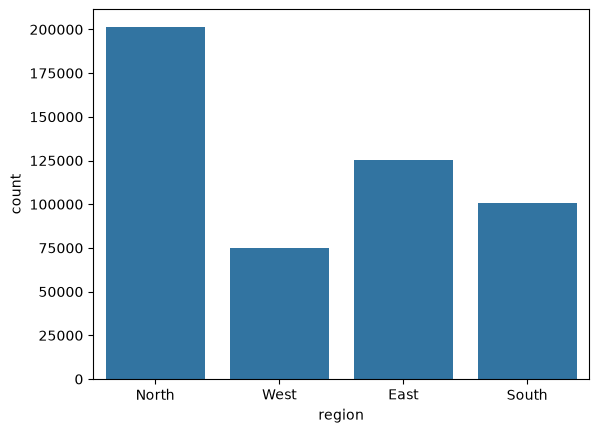

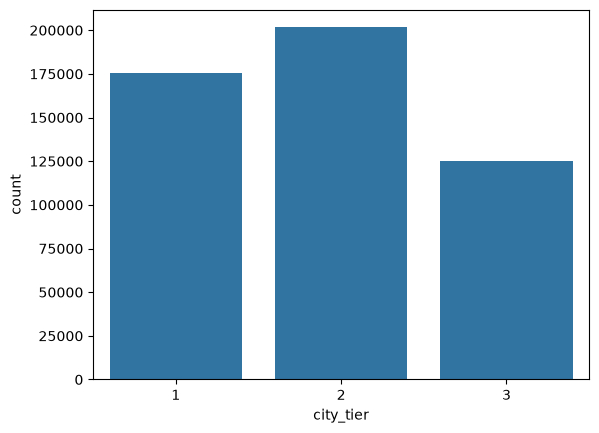

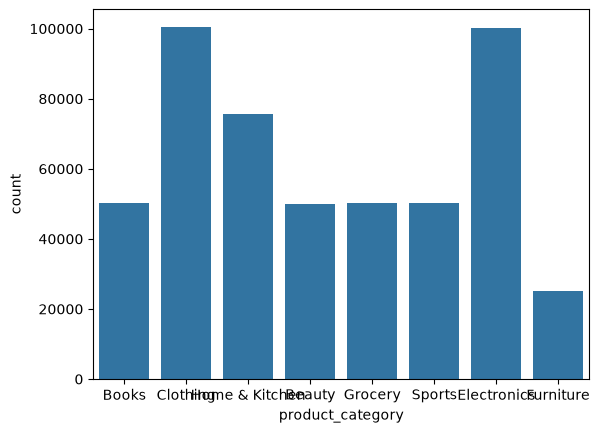

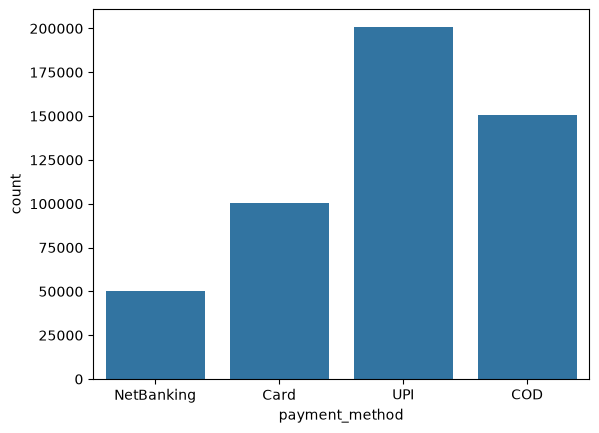

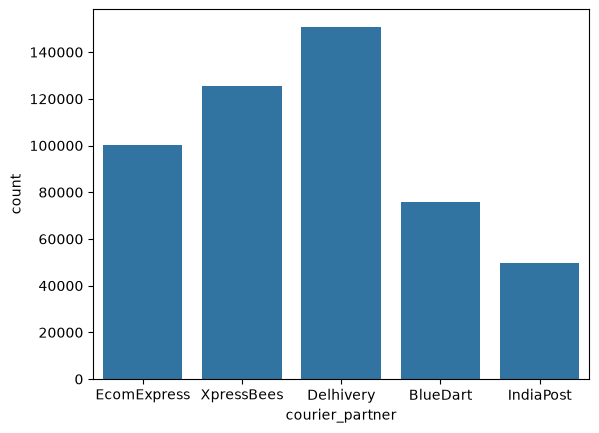

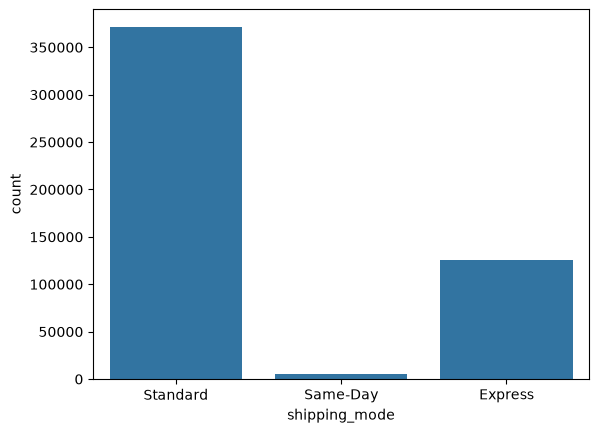

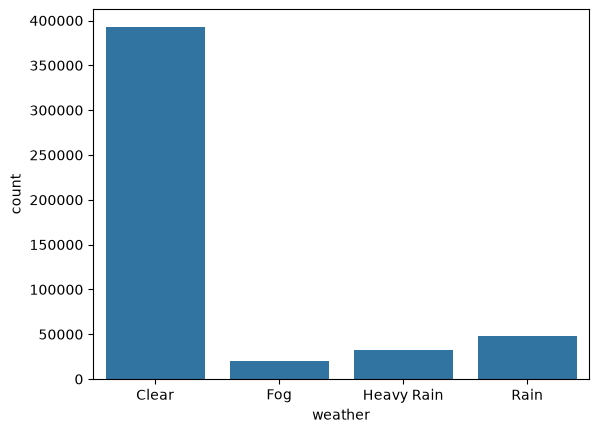

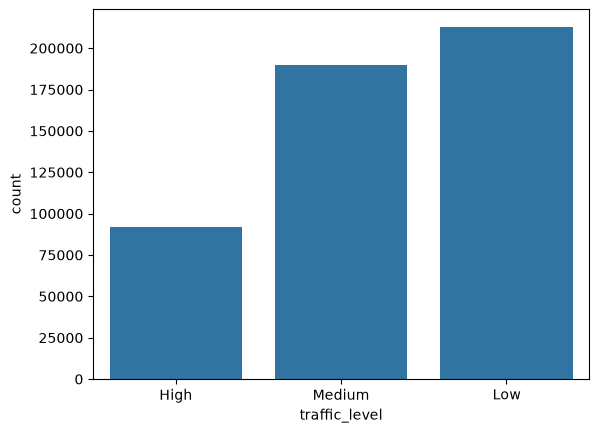

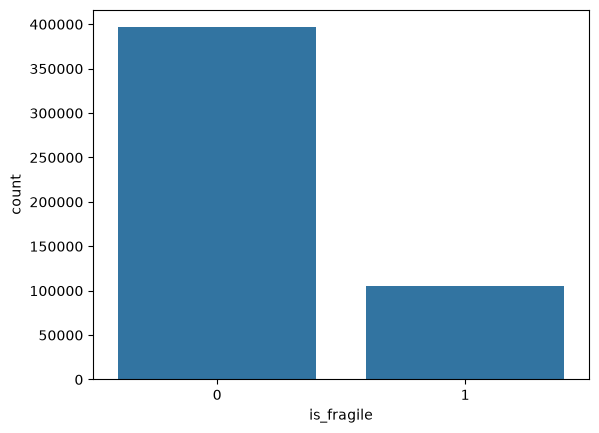

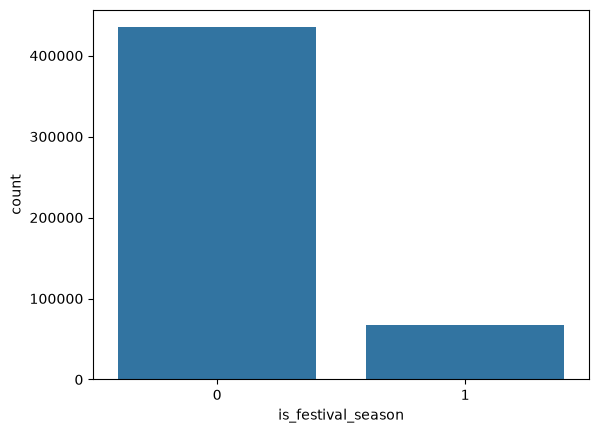

In [24]:
for col in cat_cols:
    sns.countplot(x=col, data=delivery); plt.show()

In [25]:
targets = ['actual_days', 'delay_days', 'is_late']

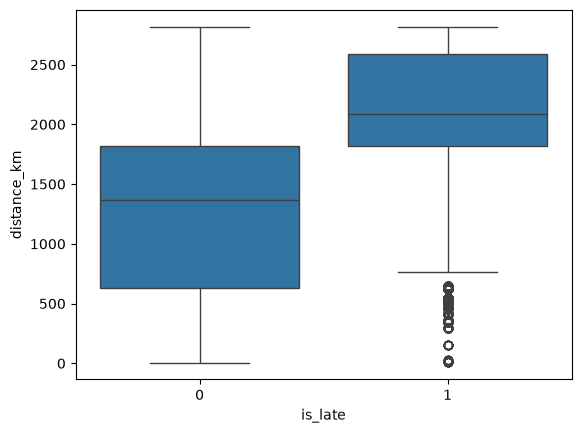

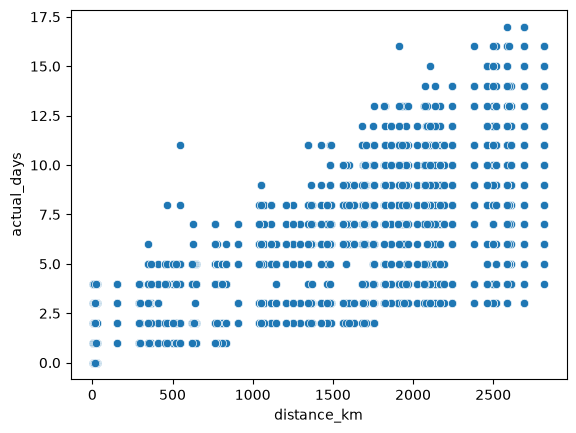

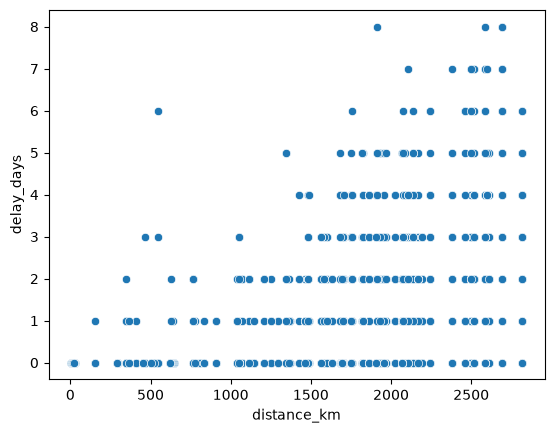

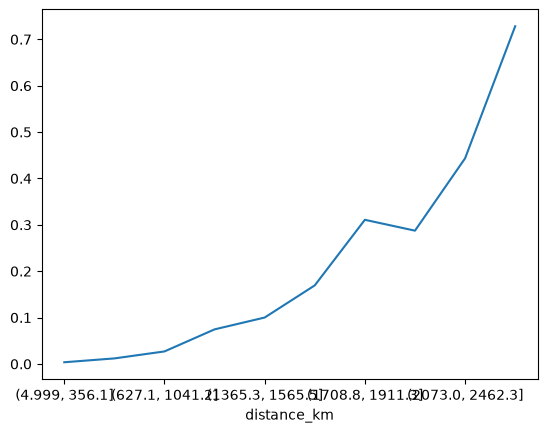

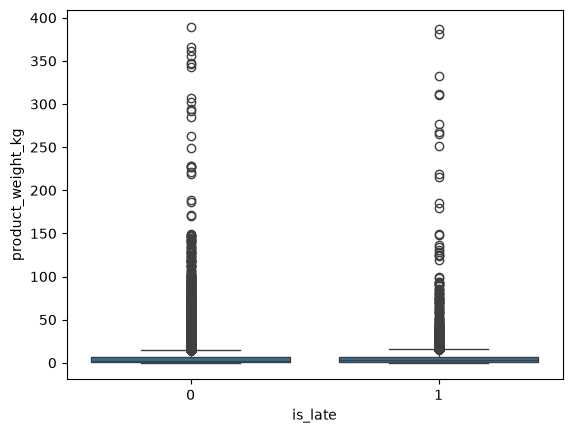

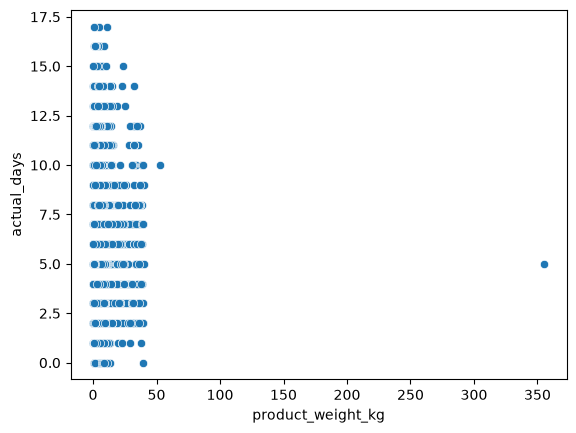

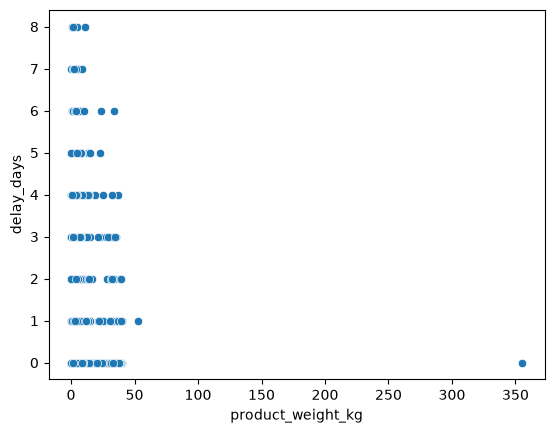

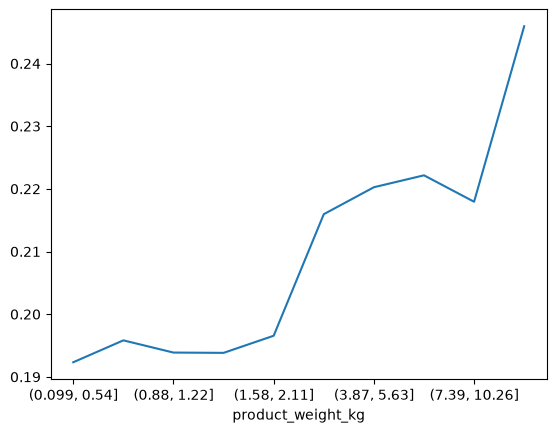

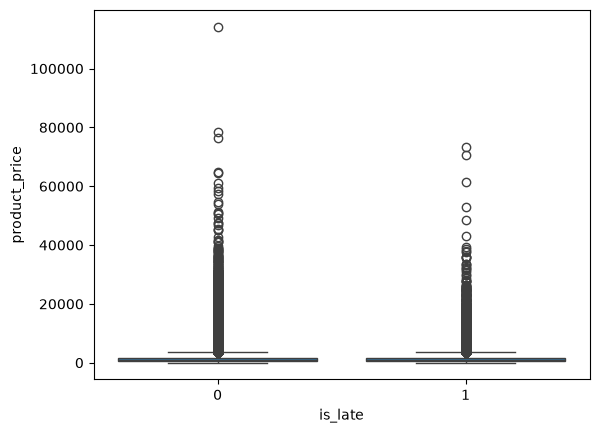

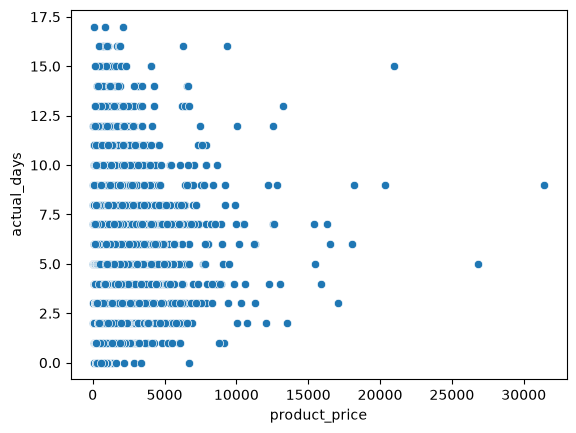

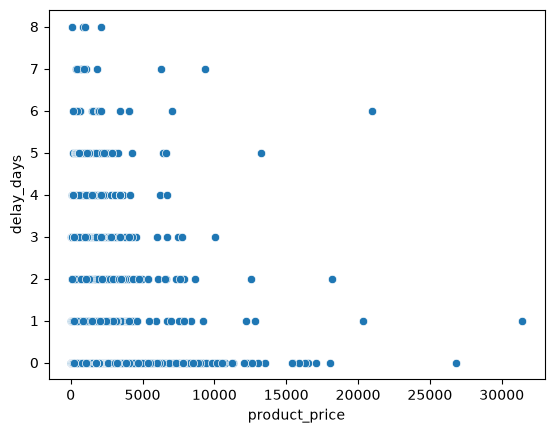

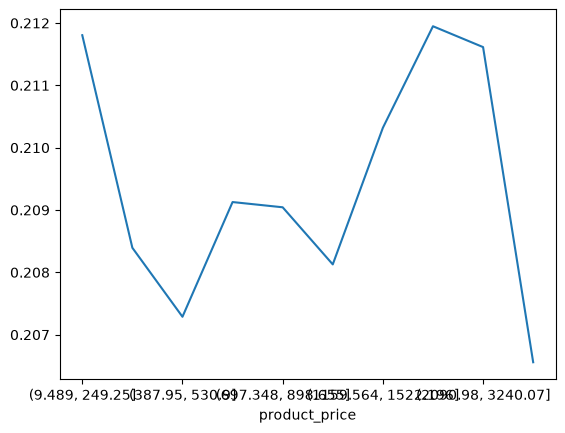

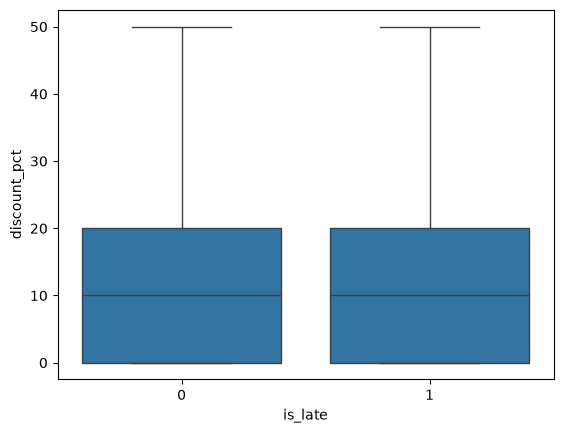

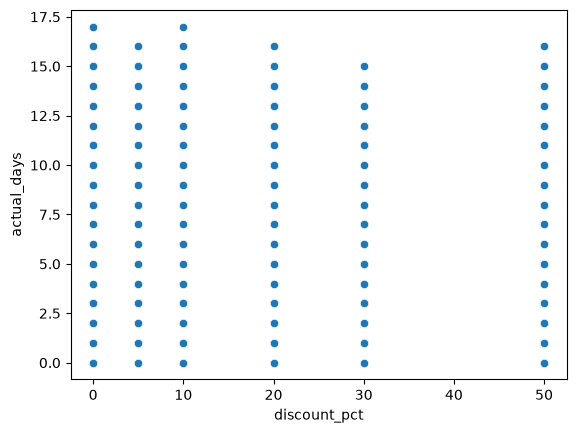

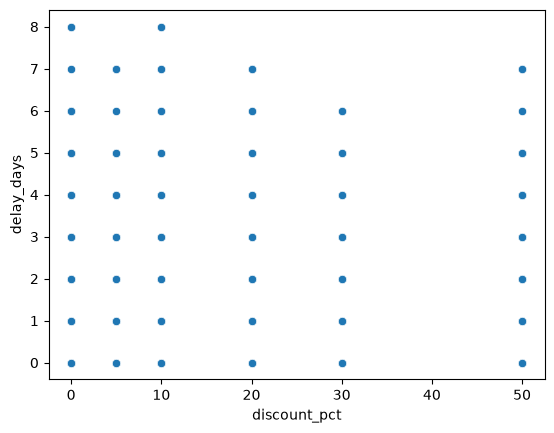

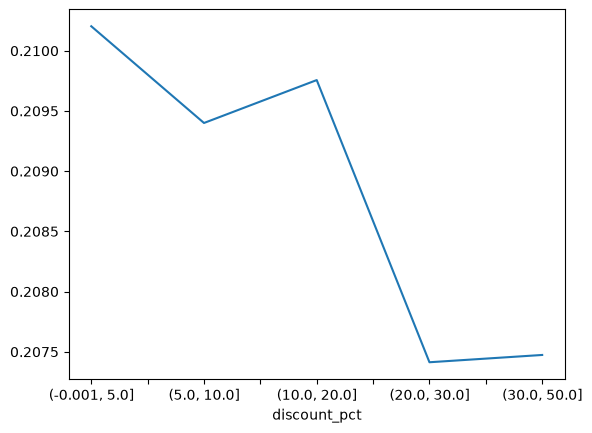

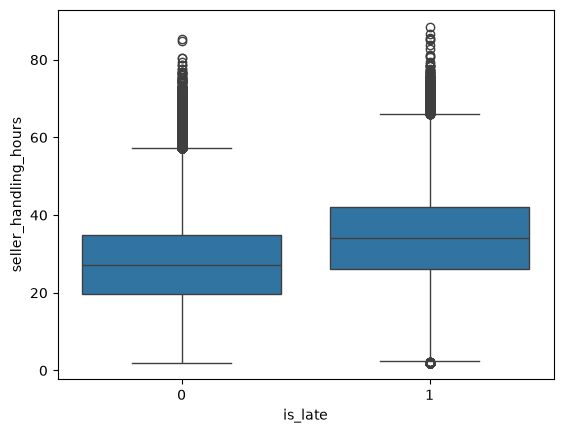

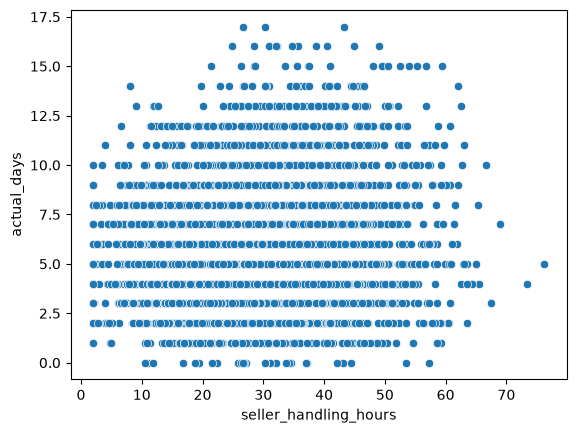

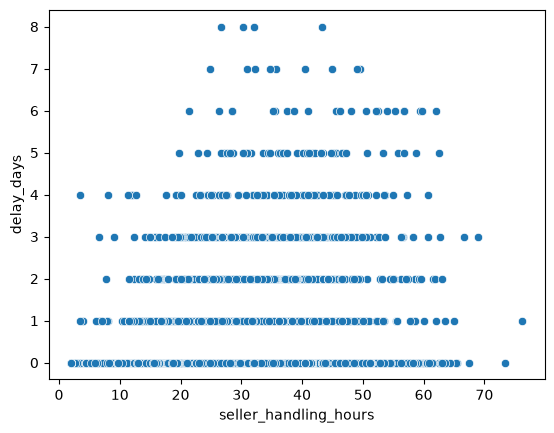

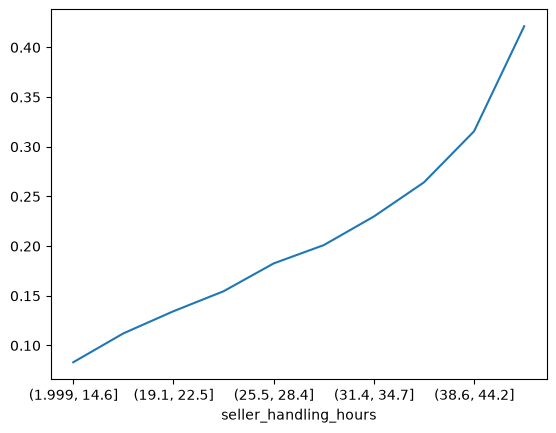

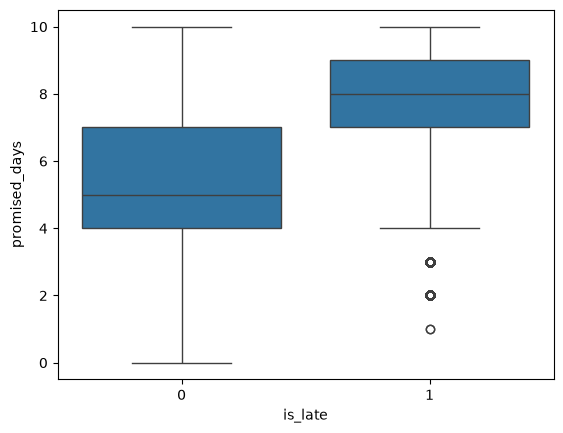

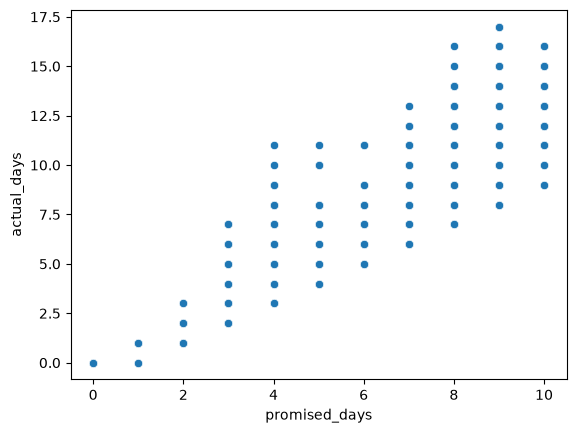

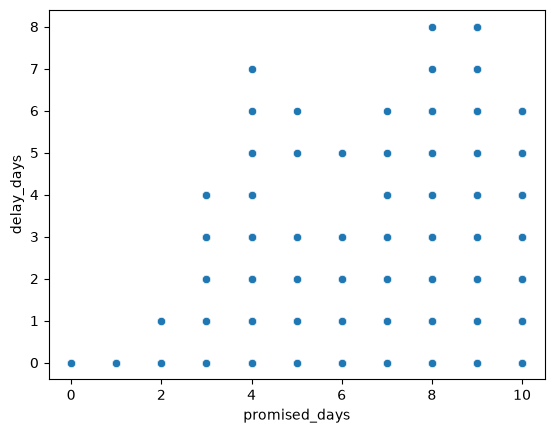

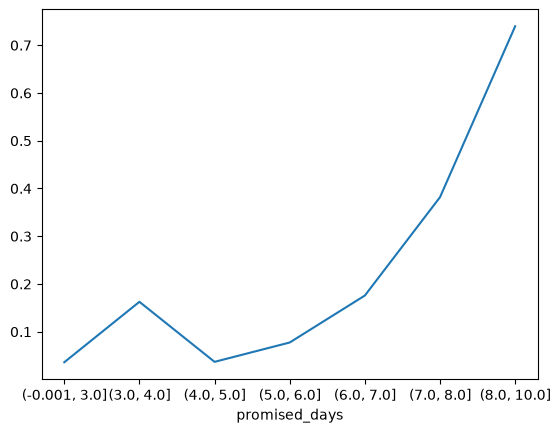

In [26]:
sample = delivery.sample(5000)

for col in num_cols:
    sns.boxplot(x='is_late', y=col, data=delivery); plt.show()                  
    sns.scatterplot(x=col, y='actual_days', data=sample); plt.show()            
    sns.scatterplot(x=col, y='delay_days', data=sample); plt.show()             
    delivery.groupby(pd.qcut(delivery[col], 10, duplicates='drop'))['is_late'].mean().plot(); plt.show()  # late rate by decile

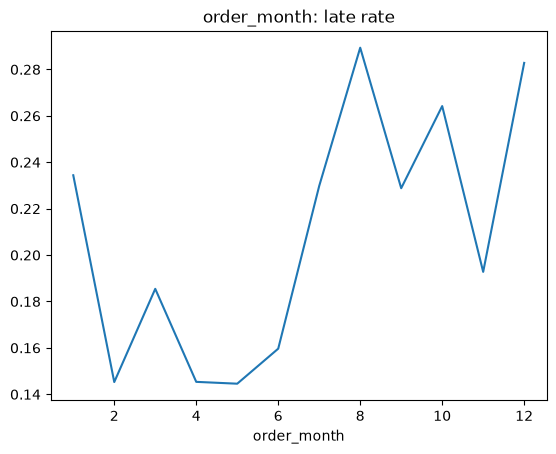

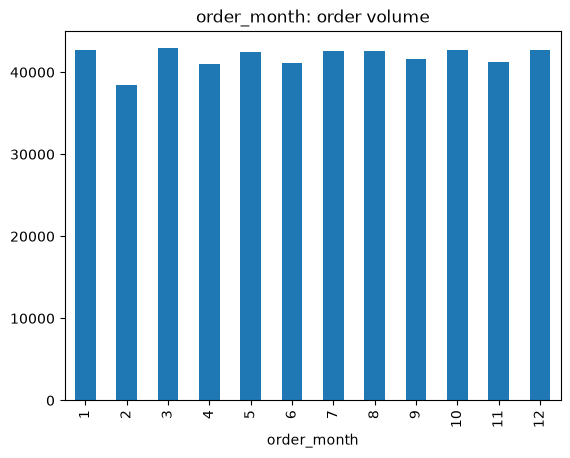

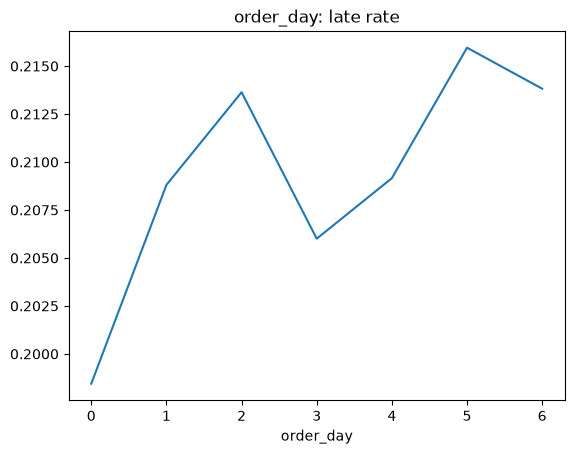

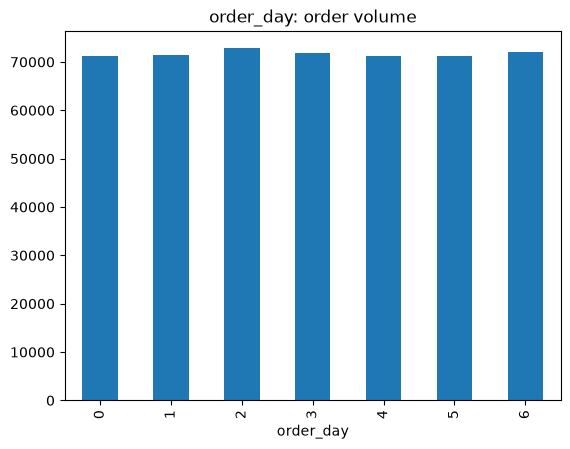

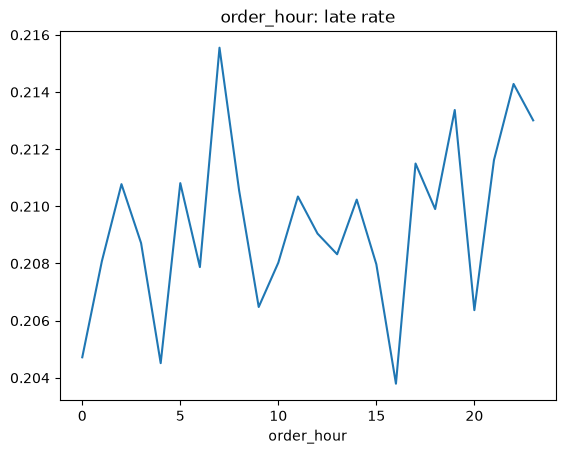

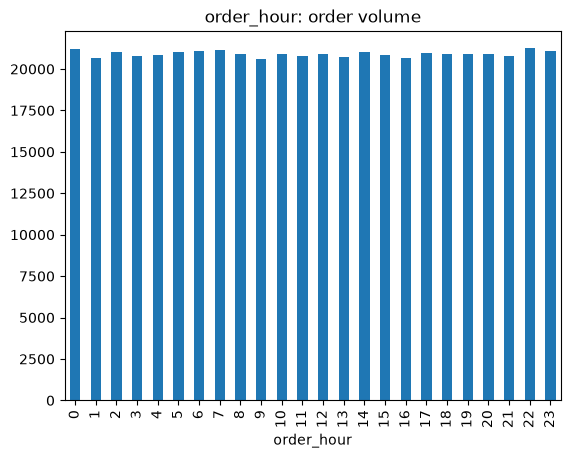

In [27]:
for col in ['order_month', 'order_day', 'order_hour']:
    delivery.groupby(col)['is_late'].mean().plot(); plt.title(col + ': late rate'); plt.show()
    delivery.groupby(col).size().plot(kind='bar'); plt.title(col + ': order volume'); plt.show()

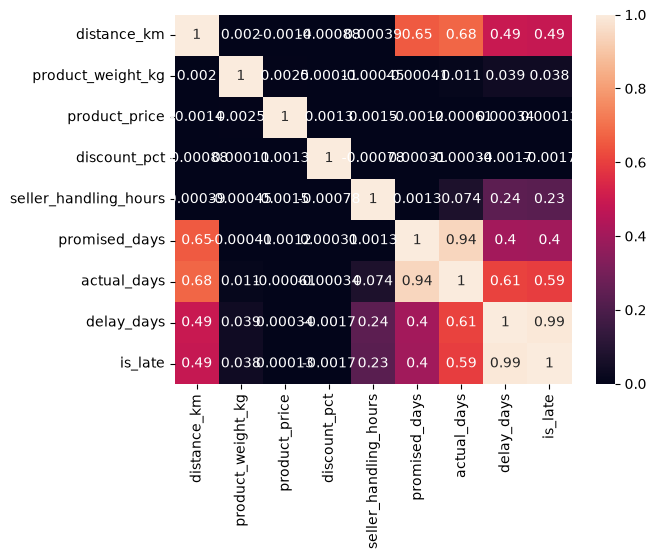

In [28]:
sns.heatmap(delivery[num_cols + targets].corr(method='spearman'), annot=True)
plt.show()

In [29]:
del2 = delivery.copy()

In [30]:
del2 = del2.drop_duplicates()
del2.duplicated().sum()

np.int64(0)

In [31]:
cols = ['product_weight_kg','seller_handling_hours','weather','traffic_level']
del2[cols].head()

,product_weight_kg,seller_handling_hours,weather,traffic_level
0,1.25,23.2,Clear,High
1,1.56,16.0,Fog,Medium
2,1.84,22.5,Clear,Medium
3,0.97,33.9,Fog,Medium
4,1.64,40.1,Heavy Rain,Medium


In [32]:
del2 = del2.dropna(subset=['product_weight_kg'])
del2['seller_handling_hours'] = del2['seller_handling_hours'].fillna(del2['seller_handling_hours'].mean())
del2['weather'] = del2['weather'].fillna('Unknown')
del2['traffic_level'] = del2['traffic_level'].fillna(del2['traffic_level'].mode()[0])
del2[cols].isnull().sum()

product_weight_kg        0
seller_handling_hours    0
weather                  0
traffic_level            0
dtype: int64

In [33]:
del2.head(50)

,order_id,order_datetime,seller_id,warehouse_city,destination_city,city_tier,region,distance_km,product_category,product_weight_kg,...,is_festival_season,promised_days,promised_delivery_date,actual_delivery_datetime,actual_days,delay_days,is_late,order_month,order_day,order_hour
0,ORD100000,2025-01-01 00:00:00,S1753,Bengaluru,Chandigarh,2,North,2462.3,Books,1.25,...,0,9,2025-01-10,2025-01-12 00:00:00,11,2,1,1,2,0
1,ORD100001,2025-01-01 00:01:00,S1895,Mumbai,Mumbai,1,West,9.7,Clothing,1.56,...,0,0,2025-01-01,2025-01-01 20:52:00,0,0,0,1,2,0
2,ORD100002,2025-01-01 00:01:00,S0122,Kolkata,Mumbai,1,West,2070.1,Clothing,1.84,...,0,8,2025-01-09,2025-01-08 00:01:00,7,0,0,1,2,0
3,ORD100003,2025-01-01 00:04:00,S0623,Delhi,Imphal,3,East,2137.8,Clothing,0.97,...,0,4,2025-01-05,2025-01-05 00:04:00,4,0,0,1,2,0
4,ORD100004,2025-01-01 00:05:00,S1868,Delhi,Shimla,3,North,347.5,Clothing,1.64,...,0,4,2025-01-05,2025-01-07 00:05:00,6,2,1,1,2,0
5,ORD100005,2025-01-01 00:05:00,S1420,Kolkata,Pathankot,3,North,2073.0,Home & Kitchen,3.42,...,0,8,2025-01-09,2025-01-11 00:05:00,10,2,1,1,2,0
6,ORD100006,2025-01-01 00:06:00,S0720,Hyderabad,Lucknow,2,North,1342.5,Beauty,1.15,...,0,6,2025-01-07,2025-01-07 00:06:00,6,0,0,1,2,0
7,ORD100007,2025-01-01 00:06:00,S0700,Hyderabad,Kolkata,1,East,1480.6,Clothing,1.96,...,0,7,2025-01-08,2025-01-08 00:06:00,7,0,0,1,2,0
9,ORD100009,2025-01-01 00:07:00,S1187,Delhi,Mumbai,1,West,1428.7,Clothing,0.27,...,0,7,2025-01-08,2025-01-08 00:07:00,7,0,0,1,2,0
10,ORD100010,2025-01-01 00:08:00,S0671,Bengaluru,Jaipur,2,North,1946.2,Books,1.43,...,0,8,2025-01-09,2025-01-09 00:08:00,8,0,0,1,2,0


In [34]:
del2['is_festival_season'] = del2['is_festival_season'].replace(0,'No')
del2['is_festival_season'] = del2['is_festival_season'].replace(1,'Yes')
del2['is_festival_season'].unique()

array(['No', 'Yes'], dtype=object)

In [35]:
q1 = del2['seller_handling_hours'].quantile(0.25)
q3 = del2['seller_handling_hours'].quantile(0.75)
iqr = q3-q1
lower = q1-1.5*iqr
upper = q3+1.5*iqr
print("lower bound:",lower)
print("upper bound:",upper)
print("Outliers:",((del2['seller_handling_hours']<lower) | (del2['seller_handling_hours']>upper)).sum())

lower bound: -2.099999999999998
upper bound: 59.5
Outliers: 3476


In [36]:
del2['seller_handling_hours'] = np.clip(del2['seller_handling_hours'],0,upper)
print("Outliers:",((del2['seller_handling_hours']<lower) | (del2['seller_handling_hours']>upper)).sum())


Outliers: 0


In [37]:
q1 = del2['product_weight_kg'].quantile(0.25)
q3 = del2['product_weight_kg'].quantile(0.75)
iqr = q3-q1
lower = q1-1.5*iqr
upper = q3+1.5*iqr
print("lower bound:",lower)
print("upper bound:",upper)
print("Outliers:",((del2['product_weight_kg']<lower) | (del2['product_weight_kg']>upper)).sum())

lower bound: -7.125000000000001
upper bound: 14.675
Outliers: 23243


In [38]:
del2['product_weight_kg'] = np.clip(del2['product_weight_kg'],0,upper)
print("Outliers:",((del2['product_weight_kg']<lower) | (del2['product_weight_kg']>upper)).sum())


Outliers: 0


In [40]:
del2.shape

(495000, 29)

In [42]:
del2.to_csv('Delivery_data_cleaned.csv',index=False)